# Plot results: see what an estimate's numbers hide

## At a glance

A table of estimates hides shape: where patients had almost no chance of an offer, how the estimate moves when you change a setting, and how often a method's interval misses. The functions in
`cleverly.plotting` draw those shapes. This page uses them on simulated data, where offering
care-transition navigation to patients going home from hospital raised a transition score by a true
1.0 point. The fit estimates 1.093 points, with a 95% confidence interval of 0.958 to 1.236. The figures check that answer.

Each figure from `cleverly.plotting` draws only numbers the fit holds: a method that reports no interval gets a hollow point and a reason, never an invented interval. A figure checks the fitted models and the characteristics you recorded, so it cannot show a confounder, a missing factor behind both the offer and the score, that nobody recorded. The figures need matplotlib, so run `pip install "cleverly[plot]"` first.

## Set up

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression

import cleverly
from cleverly import plotting
from cleverly.plotting import _core

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
print("cleverly", cleverly.__version__)

cleverly 0.2.4


## The data

In [2]:
from cleverly.datasets import make_weak_overlap

# With your own data, load your data frame here, such as frame = pd.read_csv(...).
# Real data have no `truth`, so drop every line that uses it.
frame, truth = make_weak_overlap(n=1_500, seed=21, strength=1.5)
frame = frame.rename(
    columns={
        "Y": "transition_score",
        "A": "navigation_offer",
        "W1": "discharge_risk",
        "W2": "prior_utilization",
        "W3": "medication_burden",
    }
)
covariates = ["discharge_risk", "prior_utilization", "medication_burden"]
print("rows and columns:", frame.shape)
print("column names:", list(frame.columns))
print(frame.head().round(3))
print()
print(f"share offered navigation: {frame['navigation_offer'].mean():.3f}")
print(f"true average effect of the offer (simulated data only): {truth['ate']:.3f}")

rows and columns: (1500, 5)
column names: ['transition_score', 'navigation_offer', 'discharge_risk', 'prior_utilization', 'medication_burden']
   transition_score  navigation_offer  discharge_risk  prior_utilization  medication_burden
0             3.512               1.0           0.359              1.511             -1.786
1             5.694               1.0           1.687             -0.047             -0.800
2            -1.508               0.0          -0.803             -1.083             -0.224
3             5.013               1.0           0.834              0.584              0.638
4            -0.363               0.0          -1.695             -1.571              1.554

share offered navigation: 0.489
true average effect of the offer (simulated data only): 1.000


One row is one patient discharged home, which the figures call a unit. The score has no fixed range,
so it counts points. Discharge teams offered navigation mostly to riskier patients, so the two
groups differ before the offer, and some patients were almost always or almost never offered. The
columns come from `make_weak_overlap`, and the true effect, 1.000 points, is known only because the
data are simulated.

## One fit to draw

In [3]:
from cleverly import ATE, CausalStudy, PointTreatment

# For your own data, change the column names and swap in your own learners. Leave out
# cross_fit=False, so that each row's predictions come from models trained without it.
study = CausalStudy(
    frame,
    design=PointTreatment(
        outcome="transition_score",
        treatment="navigation_offer",
        adjustment=tuple(covariates),
    ),
)
# The average effect (ATE): the offered group (1) against the not-offered group (reference 0).
effect = study.identify(ATE(reference=0))
fit_settings = {
    "outcome_learner": LinearRegression(),
    "treatment_learner": LogisticRegression(max_iter=1000),
    "cross_fit": False,
    "random_state": 21,
}
result = effect.estimate(**fit_settings)
table = result.to_frame()[["estimand", "psi", "std_err", "ci_lower", "ci_upper"]]
print(table.round(3).to_string(index=False))

estimand   psi  std_err  ci_lower  ci_upper
     ate 1.093    0.068     0.958     1.236


The question is the average effect of the offer (ATE, printed as `ate`): how much the average score
would change if every patient were offered navigation, compared with no one. `cleverly` estimates it
with targeted maximum likelihood (TMLE). It fits an outcome model, which predicts the score from the
offer and the three characteristics, and a treatment model, which predicts who got the offer. A correction step then uses the treatment model to remove the bias the outcome model leaves, weighting up patients whose own offer was unlikely. The estimate of 1.093 points, 95% interval 0.958 to 1.236, covers the true 1.000.

Both models are plain regressions. `cross_fit=False` has them predict the rows they were trained on, which is fast; on your own data, leave it out, so each row's predictions come from models trained without that row.

## How large is the effect, and how sure are we?

        method   psi  ci_lower  ci_upper
          TMLE 1.093     0.958     1.236
weighting only 1.192      none      none
true average effect: 1.000


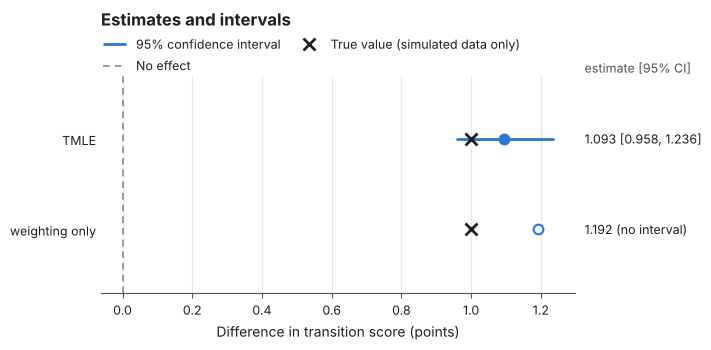

In [4]:
from cleverly import AdaptiveIPTWMethod, CrossFitting, ModelSpec, Runtime

# A second estimate of the same effect. It weights patients by their chance of the offer, and a
# small regression of the score on that chance tunes the weights.
weighting = effect.estimate(
    method=AdaptiveIPTWMethod(
        models=ModelSpec(treatment_learner=LogisticRegression(max_iter=1000)),
        cross_fitting=CrossFitting(enabled=False),
        runtime=Runtime(random_state=21, n_jobs=1),
        reduced_outcome_learner=LinearRegression(),
    )
)
fits = {"TMLE": result, "weighting only": weighting}
estimates = pd.concat(
    [fit.to_frame().assign(method=name) for name, fit in fits.items()], ignore_index=True
)
columns = ["method", "psi", "ci_lower", "ci_upper"]
print(estimates[columns].round(3).to_string(index=False, na_rep="none"))
print(f"true average effect: {truth['ate']:.3f}")
forest_fig = plotting.forest(
    result,
    weighting,
    labels=list(fits),
    outcome_label="transition score",
    units="points",
    truth=truth["ate"],
)

Each row is one estimate: a dot, a line for its 95% confidence interval. The dashed line marks no effect. The black cross marks the true value (`truth=`), which only
simulated data have, and the TMLE interval contains it.

The second row weights patients by their chance of the offer and adds a small regression of the
score on that chance, which tunes the weights (Adaptive IPTW). It has a hollow dot
and no line, because `cleverly` reports no interval for it: with an estimated treatment model, or a missingness model (who has a recorded score), no standard error is known to be valid. The figure carries no notes, so `plotting.notes(forest_fig)` gives the details: it calls the fit experimental, meaning no simulation study covers this kind of fit, and suggests DR-TMLE, a TMLE variant that corrects both models, for an interval.

## Did every kind of patient have a chance of the offer?

predicted chance of the offer, by who was actually offered:
            offered  not offered
percentile                      
5%            0.200        0.025
25%           0.497        0.109
50%           0.741        0.254
75%           0.888        0.468
95%           0.975        0.763

limits on the chance: 0.018 to 0.982
share of patients capped at a limit: 0.031


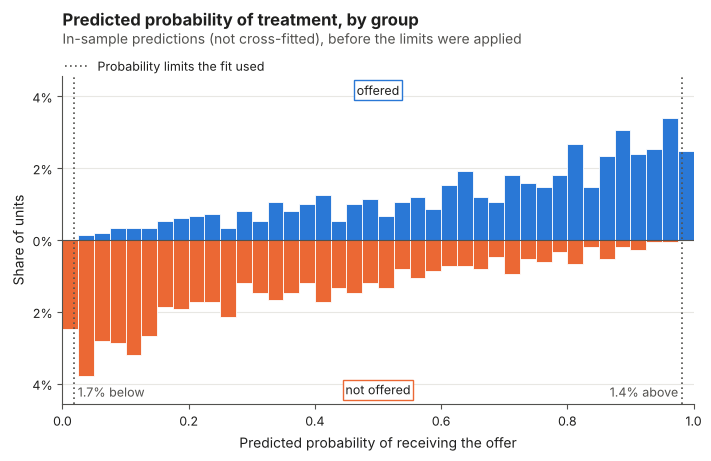

In [5]:
support = result.diagnostics.support()
chances = pd.DataFrame(support.propensity_quantiles).loc[[0.05, 0.25, 0.5, 0.75, 0.95]]
chances = chances[["treated", "control"]]
chances.columns = ["offered", "not offered"]
chances.index = ["5%", "25%", "50%", "75%", "95%"]
chances.index.name = "percentile"
print("predicted chance of the offer, by who was actually offered:")
print(chances.round(3))
print()
low, high = support.bounds
print(f"limits on the chance: {low:.3f} to {high:.3f}")
print(f"share of patients capped at a limit: {support.truncated['fraction']:.3f}")
overlap_fig = plotting.overlap(
    result, treatment_label="receiving the offer", labels={1: "offered", 0: "not offered"}
)

The treatment model gives each patient a predicted chance of the offer. The figure stacks offered
patients above the axis and the others below it, so the groups overlap where both have bars. Offered patients are scarce below about 0.2 (5% fall under 0.200), and patients without
the offer are scarce above about 0.8 (5% rise above 0.763), so the estimate leans on few patients at
both ends. The dotted lines mark the limits `cleverly` put on the chances, 0.018 and 0.982, so that
no patient's weight grows without bound. 

 The chances come from a logistic regression on three recorded characteristics, so a kind of patient it does not describe is invisible here.

## Did weighting make the two groups alike?

        covariate  smd_unweighted  smd_weighted
   discharge_risk           1.123         0.056
prior_utilization           0.720         0.185
medication_burden           0.022         0.032


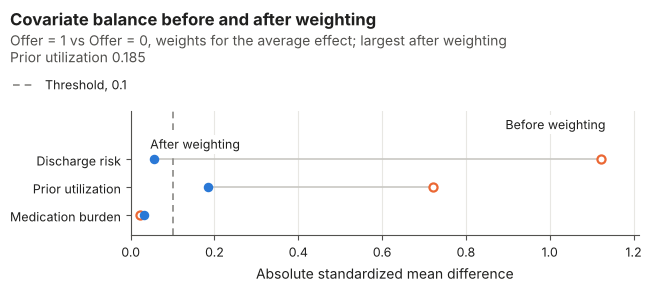

In [6]:
from cleverly.sensitivity import covariate_balance

balance = covariate_balance(result)
differences = balance.to_frame()[["covariate", "smd_unweighted", "smd_weighted"]]
print(differences.round(3).to_string(index=False))
balance_fig = balance.plot(
    treatment_label="Offer",
    labels={
        "discharge_risk": "Discharge risk",
        "prior_utilization": "Prior utilization",
        "medication_burden": "Medication burden",
    },
)

Each row is one characteristic. The hollow marker is the difference between the offered and
not-offered groups' averages, in standard deviations, before weighting. The filled marker is the
same difference after weighting each patient by the inverse of the chance of their own group, as the fit does. A filled marker left of the dashed line at 0.1 is small by the usual rule of thumb.

Discharge risk falls from 1.123 to 0.056, so weighting removed most of the difference that drove the
offers. Prior utilization falls from 0.720 to 0.185, still above the line. That is noise from a few
large weights, not a wrong model: weighting with the true chances, which only simulated data supply,
leaves about the same gap. The outcome model also adjusts for prior utilization. On real data, try a
more flexible treatment model only if a gap persists. 

## Does the answer depend on how extreme weights are capped?

 bound   psi  ci_lower  ci_upper  truncated_fraction
 0.001 1.118     0.980     1.264               0.000
 0.005 1.104     0.969     1.248               0.005
 0.010 1.099     0.964     1.242               0.013
 0.018 1.093     0.958     1.236               0.031
 0.025 1.088     0.953     1.231               0.049
 0.050 1.059     0.929     1.196               0.123
 0.100 1.026     0.909     1.145               0.238
 0.200 1.003     0.900     1.108               0.464


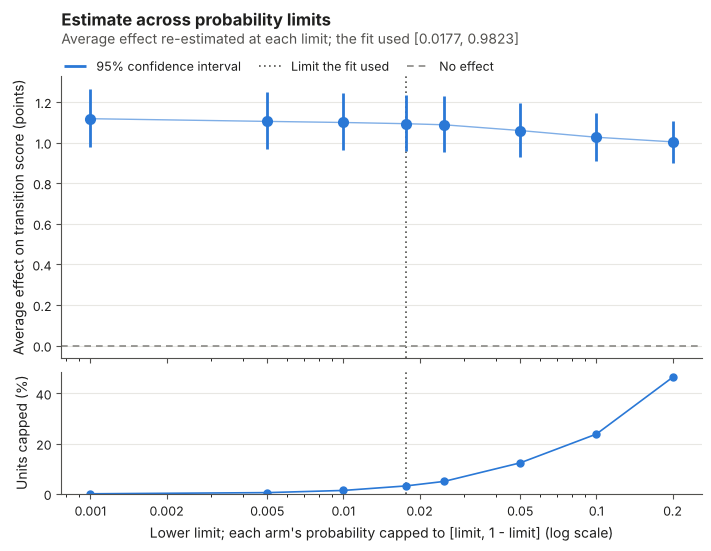

In [7]:
truncation = result.diagnostics.truncation_curve()
columns = ["bound", "psi", "ci_lower", "ci_upper", "truncated_fraction"]
print(truncation.to_frame()[columns].round(3).to_string(index=False))
truncation_fig = truncation.plot(outcome_label="transition score", units="points")

The top panel re-estimates the effect under each lower limit on the chance of the offer, and the dotted line marks the limit the fit used. The bottom panel shows the
share of patients each limit caps. The estimate moves from 1.118 under the loosest cap to 1.003
under the tightest, which caps 0.464 of patients, and every interval stays well above zero.

A tighter cap steadies the weights but can move the estimate when the true chances lie beyond the
limit. Look for a curve that stays flat across the caps you would defend. This one drifts by about
0.1 point and keeps the same conclusion.

## What if the offer were made more or less likely?

                                     estimand    psi  ci_lower  ci_upper
      ate_ipsi[half the odds vs current odds] -0.106    -0.122    -0.091
    ate_ipsi[double the odds vs current odds]  0.106     0.090     0.122
ate_ipsi[four times the odds vs current odds]  0.204     0.173     0.236


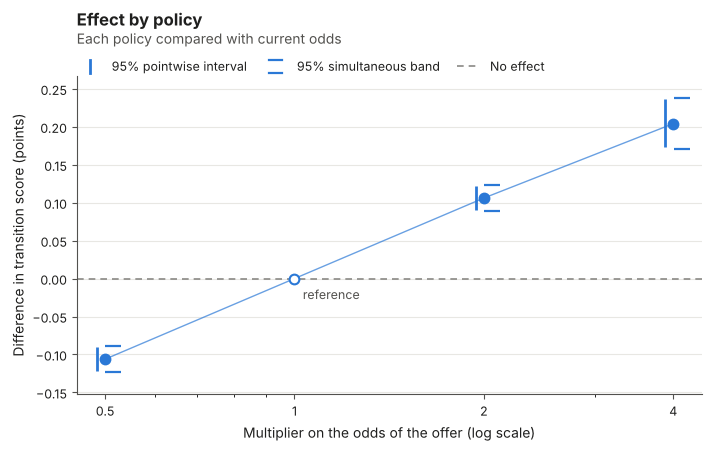

In [8]:
from cleverly import IncrementalEffect
from cleverly.interventions import Incremental

# For your own data, list the odds multipliers you could act on. 1.0 is today's practice.
odds_policies = IncrementalEffect(
    (
        Incremental(1.0, name="current odds"),
        Incremental(0.5, name="half the odds"),
        Incremental(2.0, name="double the odds"),
        Incremental(4.0, name="four times the odds"),
    ),
    reference="current odds",
)
policy_result = study.identify(odds_policies).estimate(**fit_settings)
policy_table = policy_result.to_frame()[["estimand", "psi", "ci_lower", "ci_upper"]]
print(policy_table.round(3).to_string(index=False))
policy_fig = plotting.curve(
    policy_result, outcome_label="transition score", units="points", treatment_label="the offer"
)

Instead of offering everyone or no one, this question multiplies each patient's odds of the offer, so one fit answers a family of policies together. Each dot compares a policy with
today's practice, the open marker at 1, whose effect is zero by definition. The effect rises with
the multiplier: -0.106 points at half the odds, 0.106 at double, and 0.204 at four times.

The thin bars are 95% intervals for each policy alone, and the capped bars are a band covering all three. The figure calls this kind of fit experimental. Multiplying odds never
gives a patient an offer they had no chance of, so this question needs no overlap condition.

## How strong would a missing confounder have to be?

difference in standard deviations of the score: 0.453
risk ratio, exp(0.905 * d): 1.506; nearest interval limit: 1.432
E-value of the estimate: 2.38
E-value of the interval limit: 2.22


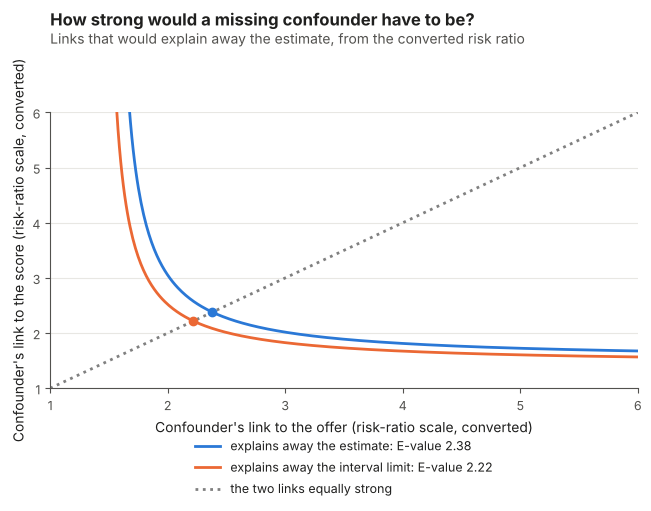

In [9]:
evalue = result.sensitivity.evalue()
low_limit = evalue.risk_ratio_ci[0]
# For a score, cleverly divides the difference by the score's standard deviation (d), then
# converts it to a rough risk ratio, exp(0.905 * d). This assumes a roughly bell-shaped score.
d = np.log(evalue.risk_ratio) / 0.905
print(f"difference in standard deviations of the score: {d:.3f}")
print(
    f"risk ratio, exp(0.905 * d): {evalue.risk_ratio:.3f}; nearest interval limit: {low_limit:.3f}"
)
print(f"E-value of the estimate: {evalue.point:.2f}")
print(f"E-value of the interval limit: {evalue.limit:.2f}")


def partner_strength(ratio, strengths):
    """The link to the score that, with a given link to the offer, explains `ratio` away."""
    return ratio * (strengths - 1.0) / (strengths - ratio)


with plotting.style():
    evalue_fig, ax = plt.subplots(figsize=(6.4, 5.0), layout="constrained")
    for ratio, value, label, color in (
        (evalue.risk_ratio, evalue.point, "the estimate", plotting.PALETTE[0]),
        (low_limit, evalue.limit, "the interval limit", plotting.PALETTE[1]),
    ):
        strengths = np.linspace(ratio + 0.02, 6.0, 400)
        ax.plot(
            strengths,
            partner_strength(ratio, strengths),
            color=color,
            label=f"explains away {label}: E-value {value:.2f}",
        )
        ax.plot([value], [value], "o", color=color, zorder=3)
    ax.plot([1, 6], [1, 6], color="grey", linestyle=":", label="the two links equally strong")
    ax.set_xlim(1, 6)
    ax.set_ylim(1, 6)
    ax.set_xlabel("Confounder's link to the offer (risk-ratio scale, converted)")
    ax.set_ylabel("Confounder's link to the score (risk-ratio scale, converted)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1, frameon=False)
    _core.header(
        ax,
        "How strong would a missing confounder have to be?",
        "Links that would explain away the estimate, from the converted risk ratio",
    )

A missing confounder could explain the estimate away if it were linked strongly enough to both the
offer and the score. The figure measures each link as a risk ratio (how many times likelier one group is to be offered, or to score high, than another) and draws the pairs of strengths that would
just do it. A confounder on or beyond the curve for the estimate could explain it away, and one beyond the curve for the interval limit could move that limit to zero. The dots, where the two links are equal, are the E-values: 2.38 for the estimate and 2.22 for the interval
limit nearest zero. 

The score is not yes or no, so `cleverly` converts the difference to a rough risk ratio. It divides
the difference by the score's standard deviation, 0.453 here, and maps that to a risk ratio of 1.506
by exp(0.905 × 0.453). The mapping assumes a roughly bell-shaped score, so read the E-values as a
rough guide. The notebook draws this figure itself.

## How far could hidden confounding move the answer?

 gamma  lower  upper  lower_limit  upper_limit
  1.00  1.061  1.061        0.909        1.213
  1.10  0.987  1.139        0.839        1.295
  1.25  0.889  1.244        0.744        1.408
  1.50  0.747  1.395        0.607        1.574
  2.00  0.517  1.628        0.386        1.832
  3.00  0.214  1.956        0.090        2.195


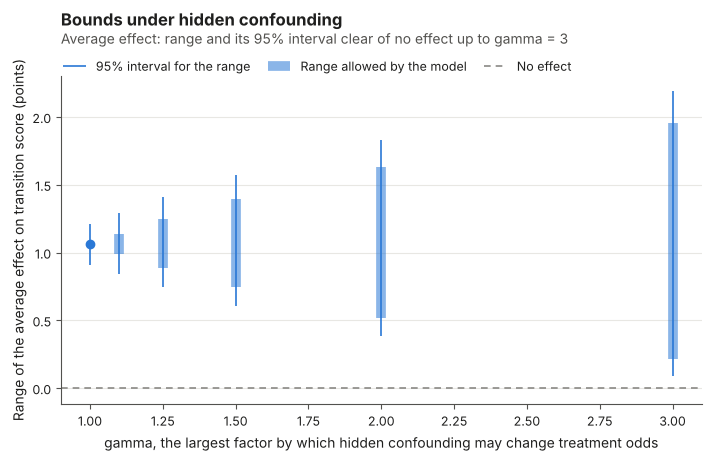

In [10]:
gammas = (1.0, 1.1, 1.25, 1.5, 2.0, 3.0)
gamma_bounds = result.sensitivity.marginal_bounds(gamma=gammas)
columns = ["gamma", "lower", "upper", "lower_limit", "upper_limit"]
print(gamma_bounds.to_frame()[columns].round(3).to_string(index=False))
gamma_fig = gamma_bounds.plot(outcome_label="transition score", units="points")

Gamma is the largest factor by which a hidden confounder could change a patient's odds of the offer,
beyond what the recorded characteristics explain. At each gamma the thick bar is the range of
effects the model allows, and the thin line is a 95% interval that covers the whole range. At gamma
1, with no hidden confounding, the range is one dot at 1.061. That dot comes from a simpler
estimator, cross-fitted AIPW (an outcome model corrected by a treatment model), run on the bound's
own data split, so it differs a little from the TMLE value.

The range widens as gamma grows, to 0.214 to 1.956 at gamma 3, where the lowest interval limit is
still above zero, at 0.090. So the effect stays positive up to gamma 3, while its size could run
from about 0.1 to 2.2. The figure calls the interval descriptive: no simulation study covers it for this kind of fit.

## What if we add a confounder we invent?

 treatment_strength  outcome_strength  estimate  displacement
                0.0               0.0     1.093         0.000
                0.0               0.5     1.102         0.009
                0.0               1.0     1.111         0.018
                0.0               2.0     1.131         0.038
                0.1               0.0     0.549        -0.544
                0.1               0.5     0.590        -0.503
                0.1               1.0     0.638        -0.455
                0.1               2.0     0.733        -0.360
                0.2               0.0     0.454        -0.639
                0.2               0.5     0.467        -0.626
                0.2               1.0     0.482        -0.611
                0.2               2.0     0.511        -0.582
                0.4               0.0     0.142        -0.951
                0.4               0.5     0.152        -0.941
                0.4               1.0     0.163        -0.930
        

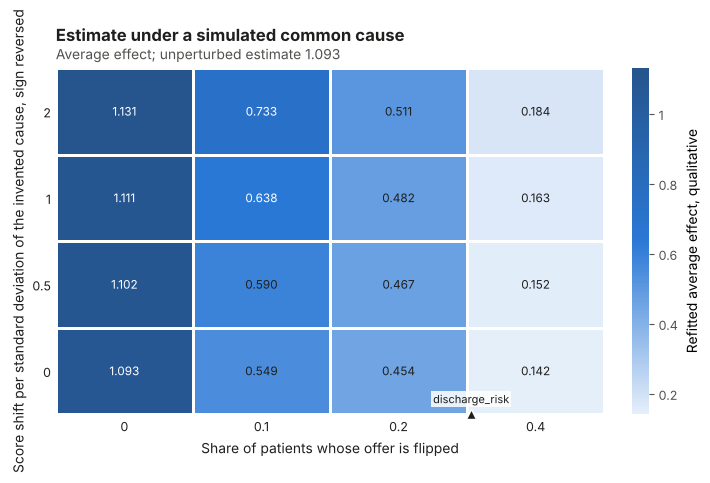

In [11]:
from cleverly.sensitivity import ConfounderStrengthGrid

# For your own data, name your strongest recorded confounder in benchmark_covariates.
surface = result.sensitivity.simulated_confounding(
    grid=ConfounderStrengthGrid(treatment=(0.0, 0.1, 0.2, 0.4), outcome=(0.0, 0.5, 1.0, 2.0)),
    benchmark_covariates=("discharge_risk",),
    random_state=21,
)
cells = surface.to_frame()
shown = ["treatment_strength", "outcome_strength", "estimate", "displacement"]
print(cells[shown].round(3).to_string(index=False))
print()
# The figure draws an outcome strength with its sign reversed, as its y label says.
recorded = surface.calibration_frame()[["covariate", "role", "strength"]]
recorded["drawn_at"] = np.where(
    recorded["role"] == "outcome", -recorded["strength"], recorded["strength"]
)
print(recorded.round(3).to_string(index=False))
surface_fig = plotting.confounding(
    surface,
    xlabel="Share of patients whose offer is flipped",
    ylabel="Score shift per standard deviation of the invented cause, sign reversed",
)

`cleverly` can add an invented one to the data and
re-estimate. Each cell is one invented confounder: the horizontal axis is the share of patients whose offer is flipped, those highest on the invented cause, and the vertical axis is how strongly it shifts the score, per standard deviation (the usual spread) of that cause. The
bottom-left cell is the unchanged estimate, 1.093.

The estimate shrinks as more offers are flipped, to 0.142 at 0.4, but no
cell crosses zero. The triangle marks the recorded `discharge_risk` at 0.306 on the horizontal axis,
a yardstick for the invented strengths. Its strength on the score, 1.764 in the table, lies beyond
the vertical axis, so `plotting.notes(surface_fig)` lists it as -1.76, because the axis counts a shift that lowers the
score as positive. The colour bar calls the map qualitative: neither a bound nor an interval.

## What if the missing answers differ from the recorded ones?

In [12]:
from cleverly.datasets import make_missing_outcome

survey, survey_truth = make_missing_outcome(n=1_500, seed=71)
survey = survey.rename(
    columns={
        "Y": "satisfaction",
        "A": "navigation_offer",
        "W1": "discharge_risk",
        "W2": "prior_utilization",
        "W3": "medication_burden",
        "Delta": "responded",
    }
)
survey_study = CausalStudy(
    survey,
    design=PointTreatment(
        outcome="satisfaction",
        treatment="navigation_offer",
        adjustment=tuple(covariates),
        missingness="responded",
    ),
)
survey_result = survey_study.identify(ATE(reference=0)).estimate(
    missingness_learner=LogisticRegression(max_iter=1000), **fit_settings
)
print(f"share of satisfaction scores missing: {1 - survey['responded'].mean():.3f}")
print(
    survey_result.to_frame()[["estimand", "psi", "ci_lower", "ci_upper"]]
    .round(3)
    .to_string(index=False)
)

share of satisfaction scores missing: 0.222
estimand   psi  ci_lower  ci_upper
     ate 1.132     1.008     1.255


This question needs missing outcomes, so it uses a second simulated dataset. It is a satisfaction
survey in which 0.222 of the scores are missing because the patient did not answer. The main
analysis assumes that a patient who did not answer would have scored like an answering patient with
the same recorded characteristics (missing at random). It estimates 1.132, with an interval of 1.008
to 1.255. `responded` marks who answered, and `missingness_learner` models who answers.

 gamma    psi
   0.0  1.132
   0.5  0.860
   1.0  0.588
   1.5  0.344
   2.0  0.148
   2.5  0.002
   3.0 -0.100


gamma at which the estimate reaches 0: 2.507


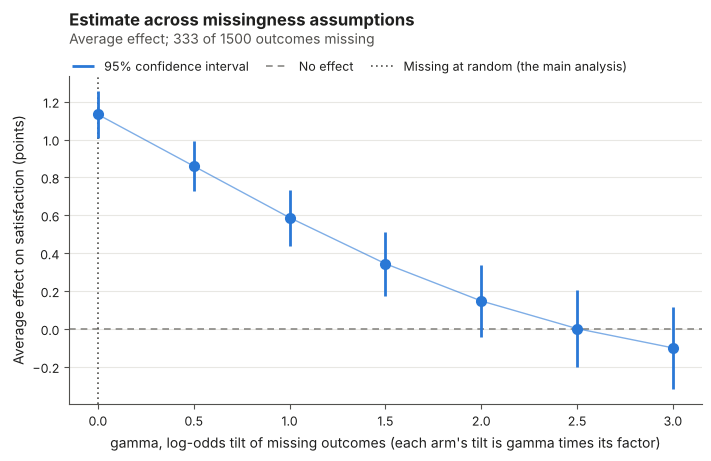

In [13]:
from cleverly.sensitivity import missingness_tilt

# A positive gamma lowers the missing scores of patients who were offered and leaves those of
# patients who were not offered as the main analysis assumes. For your own data, choose the
# direction you can defend.
direction = {0: 0.0, 1: -1.0}
tilt = missingness_tilt(survey_result, (0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0), arm_gamma=direction)
print(tilt.to_frame()[["gamma", "psi"]].round(3).to_string(index=False))
tipping = survey_result.sensitivity.tipping_gamma(arm_gamma=direction)
print(f"gamma at which the estimate reaches 0: {tipping:.3f}")
tilt_fig = tilt.plot(outcome_label="satisfaction", units="points")

Gamma measures how far the missing scores differ from that assumption. It shifts the logit of each
missing score, after the score is rescaled to 0 to 1 by its bounds, and gamma 0 is the main
analysis. Here a positive gamma lowers the missing scores of offered patients and leaves the others
as the main analysis assumes. The estimate falls from 1.132 and crosses zero at gamma 2.507, just
after the point at 2.5. Every point has its own interval: at each gamma the estimate gets a new
correction step for the moved assumption. No simulation study yet checks these intervals for this
kind of fit, so the figure calls them descriptive.

The figure cannot say which gamma is plausible. That takes knowledge of why patients did not answer. The [missing survey answers](survey-nonresponse.ipynb) page turns gamma into a drop in the
average missing score.

## Do a method's intervals cover the true value?

true average effect: 1.750
intervals that cover it: 44% of 100
intervals wholly below it: 56
intervals wholly above it: 0


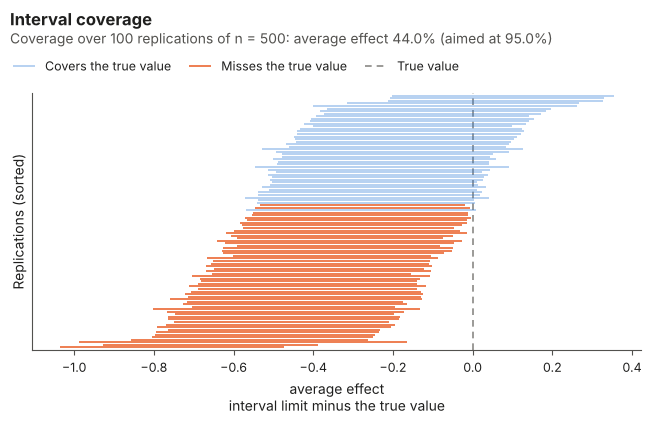

In [14]:
from cleverly.datasets import nonlinear_dgp
from cleverly.estimators import TMLE
from cleverly.validation import CoverageStudy

# A simulation: draw 100 fresh samples of 500 patients from a process whose answer is known, fit
# the same linear models to each, and keep every interval.
coverage_study = CoverageStudy(
    dgp=nonlinear_dgp(),
    estimator=lambda: TMLE(
        outcome_learner=LinearRegression(),
        treatment_learner=LogisticRegression(max_iter=1000),
        cross_fit=False,
    ),
    n=500,
    n_replicates=100,
    estimands=("ate",),
    seed=7,
).run()
records = pd.DataFrame(
    [
        {"low": record.lower, "high": record.upper, "covered": record.covered}
        for record in coverage_study.replications
    ]
)
truth_ate = coverage_study.replications[0].truth
print(f"true average effect: {truth_ate:.3f}")
print(f"intervals that cover it: {records['covered'].mean():.0%} of {len(records)}")
print(f"intervals wholly below it: {(records['high'] < truth_ate).sum()}")
print(f"intervals wholly above it: {(records['low'] > truth_ate).sum()}")
zipper_fig = plotting.zipper(coverage_study, labels={"ate": "average effect"})

This question needs a process whose answer you know, so it checks a method on simulated data. Each
line is the interval from one simulated sample, drawn relative to the true value (the dashed line)
and sorted by its centre, and orange lines miss. Only 44% of the 100 intervals cover the true effect
of 1.750, against the 95% aimed at, and all 56 misses lie below it.

Misses piled at one end mean the estimates are biased, here because both models are wrong: the
process is nonlinear in the outcome and in the treatment, and linear models follow neither. Misses split between both ends would mean intervals that are too narrow, which a coverage number alone cannot tell apart.

## What the figures can and can't tell you

The page shows one simulated draw, so each reading describes these data only. The three confounding
figures show how strong a missing confounder would have to be, or how far an invented one moves the
estimate, and none shows whether one exists.  On real data there is no true value, so
`truth=` drops out and the last figure needs a simulation that you design.

## Where to go next

The [one treatment, one outcome](point-treatment-tmle.ipynb) page uses the overlap figure and a
confounding map on a fuller analysis, and [who gains most from a coupon](conditional-effects.ipynb)
draws an effect over age. The [plotting reference](../api/plotting.md) lists every function, including the
ones this page skips, and [results, inference, and assessment](../user-guide/results-assessment.md)
explains the summaries the figures draw from.